# Card: Godot editor plugin classes

Left side: things **you write** and Godot calls. Right side: things that **already exist** and you ask for.

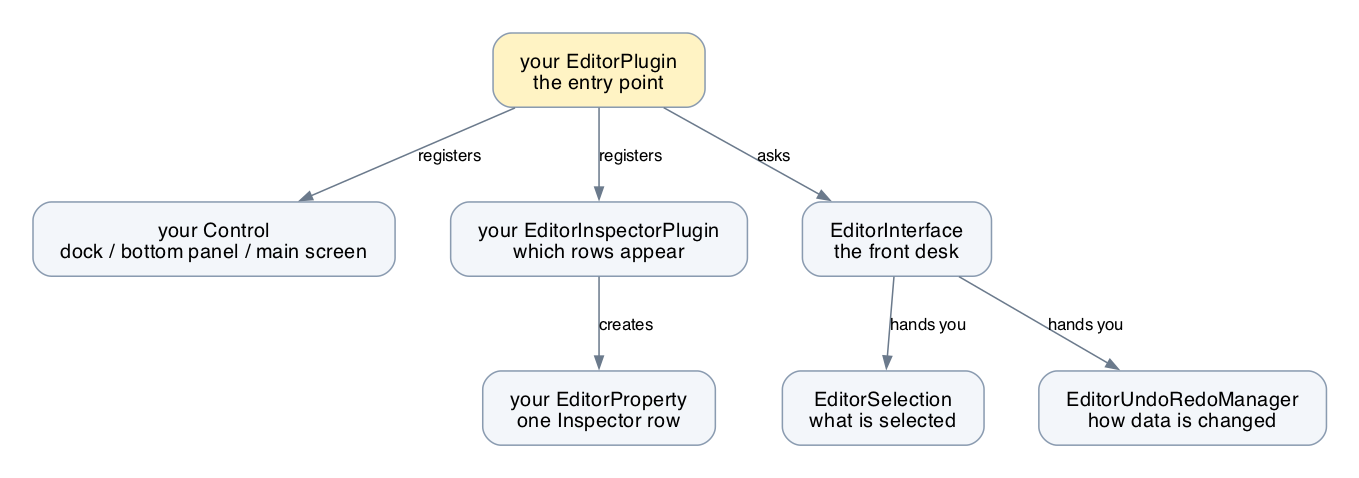

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  rankdir=TB;
  plugin [label="your EditorPlugin\nthe entry point", fillcolor="#fff3c4"];
  dock [label="your Control\ndock / bottom panel / main screen"];
  insp [label="your EditorInspectorPlugin\nwhich rows appear"];
  prop [label="your EditorProperty\none Inspector row"];
  iface [label="EditorInterface\nthe front desk"];
  sel [label="EditorSelection\nwhat is selected"];
  undo [label="EditorUndoRedoManager\nhow data is changed"];
  plugin -> dock [label="registers"];
  plugin -> insp [label="registers"];
  insp -> prop [label="creates"];
  plugin -> iface [label="asks"];
  iface -> sel [label="hands you"];
  iface -> undo [label="hands you"];
}
```

</details>

| Class | Kind | What it is | Key functions | In the RPGM plugin |
|---|---|---|---|---|
| `EditorPlugin` | extend | Entry point, registers everything | `_enter_tree`, `_exit_tree`, `add_control_to_bottom_panel`, `add_inspector_plugin` | `plugin.gd` |
| `EditorInterface` | ask | Front desk to every editor service | `get_selection`, `get_editor_undo_redo`, `get_editor_theme`, `get_editor_scale` | every file |
| `EditorSelection` | ask + connect | What is selected in the Scene tree | `get_selected_nodes`, signal `selection_changed` | the dock |
| `EditorUndoRedoManager` | ask + connect | The right way to change scene data | `create_action`, `add_do_property`, `commit_action`, signal `history_changed` | queue editor |
| `EditorInspectorPlugin` | extend | Decides which Inspector rows appear | `_can_handle`, `_parse_property`, `add_property_editor`, `add_custom_control` | the two inspector files |
| `EditorProperty` | extend | One Inspector row for one property | `_update_property`, `emit_changed`, `get_edited_object`, `set_bottom_editor` | lambda queue row |
| `EditorInspector` | ask | The Inspector panel; makes stock rows | `instantiate_property_editor`, signal `property_edited` | values pane |
| `EditorFileSystem` | ask + connect | The editor's view of `res://` | `scan`, signal `filesystem_changed` | not used |
| `EditorSettings` | ask | The user's editor preferences | `get_setting`, `set_setting` | not used |
| `EditorScript` | extend | One-off script, run with File > Run | `_run`, `get_scene` | not used |
